# EARLY BIRD — Prediksi Harga Rumah


Notebook ini menggabungkan seluruh proses **EDA → Direct Modeling (5 model) → Preprocessing & Modeling Ulang (5 model) → Feature Selection → GridSearchCV & Evaluasi → Ekspor Model untuk Streamlit**.

**Prinsip evaluasi:** menggunakan satu split tetap (**train 70%, validasi 15%, test 15%**); preprocessing, feature selection dan cross-validation menggunakan data training. Test dipakai **sekali pada model final**. Tidak mengklaim skor model baru sama dengan model Streamlit lama sebelum diuji.



---

## BAGIAN 1 — EDA & DATA QUALITY

Memahami data mentah, harga, missing value, duplikat, dan tiga insight.

### Persiapan lingkungan, dataset, dan folder hasil
Cukup dilakukan **sekali** untuk seluruh notebook.

In [1]:
from pathlib import Path
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Colab: simpan artefak lengkap di Drive supaya tidak hilang saat runtime berakhir.
# Lokal: ganti EARLYBIRD_ROOT jika perlu.
if os.getenv('EARLYBIRD_ROOT'):
    PROYEK = Path(os.getenv('EARLYBIRD_ROOT'))
else:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        PROYEK = Path('/content/drive/MyDrive/EarlyBird_Bengkod')
    except ImportError:
        PROYEK = Path('EarlyBird_Bengkod')

DATA = PROYEK / 'data'
HASIL = PROYEK / 'hasil'
DATA.mkdir(parents=True, exist_ok=True)
HASIL.mkdir(parents=True, exist_ok=True)
print('Folder proyek:', PROYEK)

Mounted at /content/drive
Folder proyek: /content/drive/MyDrive/EarlyBird_Bengkod


In [2]:
CSV = DATA / 'Raw-Final-Rumah.csv'
if not CSV.exists():
    # Jika file sudah ada di runtime Colab, gunakan tanpa upload ulang.
    kandidat = [Path('/content/Raw-Final-Rumah.csv'), Path.cwd() / 'Raw-Final-Rumah.csv']
    sumber_lokal = next((p for p in kandidat if p.exists()), None)
    if sumber_lokal is not None:
        import shutil
        if sumber_lokal.resolve() != CSV.resolve():
            shutil.copy2(sumber_lokal, CSV)
    else:
        try:
            from google.colab import files
            print('Unggah file Raw-Final-Rumah.csv:')
            file_upload = files.upload()
            if 'Raw-Final-Rumah.csv' not in file_upload:
                raise FileNotFoundError('Pilih file bernama Raw-Final-Rumah.csv')
            import shutil
            shutil.copyfile('Raw-Final-Rumah.csv', CSV)
        except ImportError:
            raise FileNotFoundError(f'Salin Raw-Final-Rumah.csv ke {CSV}')

df = pd.read_csv(CSV, dtype=str)
print('Ukuran data:', df.shape)
display(df.head())

Ukuran data: (40200, 8)


,Harga,Kamar Tidur,Kamar Mandi,Garasi,Luas Tanah,Luas Bangunan,Kecamatan,Page
0,"2,5 Miliar",4,3,10,LT : 438 m²,LB : 110 m²,Tapos,129
1,385 Juta,3,2,1,LT : 50 m²,LB : 60 m²,Pancoran Mas,129
2,385 Juta,3,2,1,LT : 50 m²,LB : 60 m²,Cipayung,129
3,385 Juta,3,2,1,LT : 50 m²,LB : 60 m²,Rangkapanjaya,129
4,385 Juta,3,2,1,LT : 50 m²,LB : 60 m²,Pancoran Mas,129


## 2. Memahami struktur data
Seperti latihan di kelas, kita mulai dengan melihat bentuk tabel, tipe data, dan statistik. Karena nilai angka masih dalam teks, statistik numerik belum langsung lengkap.

In [3]:
print('Dimensi:', df.shape)
print('Nama kolom:', df.columns.tolist())
df.info()
display(df.tail())
display(df.describe(include='all').T)

Dimensi: (40200, 8)
Nama kolom: ['Harga', 'Kamar Tidur', 'Kamar Mandi', 'Garasi', 'Luas Tanah', 'Luas Bangunan', 'Kecamatan', 'Page']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40200 entries, 0 to 40199
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Harga          40200 non-null  object
 1   Kamar Tidur    40191 non-null  object
 2   Kamar Mandi    35797 non-null  object
 3   Garasi         35011 non-null  object
 4   Luas Tanah     32501 non-null  object
 5   Luas Bangunan  24598 non-null  object
 6   Kecamatan      40200 non-null  object
 7   Page           40200 non-null  object
dtypes: object(8)
memory usage: 2.5+ MB


,Harga,Kamar Tidur,Kamar Mandi,Garasi,Luas Tanah,Luas Bangunan,Kecamatan,Page
40195,756 Juta Total,LT:168 m²,NaN,NaN,NaN,NaN,Cilodong,910
40196,"3,9 Miliar",4,2,2,LT : 375 m²,LB : 221 m²,Cinere,910
40197,7 Miliar,5,4,1,LT : 500 m²,LB : 568 m²,Cinere,910
40198,"8,5 Miliar",5,5,2,LT : 770 m²,LB : 345 m²,Cinere,910
40199,550 Juta,LB:25 m²,NaN,NaN,NaN,NaN,Margonda,910


,count,unique,top,freq
Harga,40200,2432,"1,2 Miliar",765
Kamar Tidur,40191,1322,3,13022
Kamar Mandi,35797,688,2,11133
Garasi,35011,1085,1,15286
Luas Tanah,32501,1327,LT : 60 m²,1574
Luas Bangunan,24598,557,LB : 40 m²,1134
Kecamatan,40200,38,Cinere,8602
Page,40200,2010,910,20


## 3. Cek missing value dan duplikat
**Tidak langsung `dropna()`** seperti contoh sederhana latihan, karena ada informasi LT/LB yang bergeser ke kolom lain. Kolom `Page` berasal dari scraping sehingga duplikat juga diperiksa tanpa kolom tersebut.

Duplikat semua kolom: 1525
Duplikat tanpa Page: 9478


,Masalah,Jumlah baris
0,Luas Bangunan,15602
1,Luas Tanah,7699
2,Garasi,5189
3,Kamar Mandi,4403
4,Kamar Tidur,9
5,Harga,0
6,Kecamatan,0
7,Page,0


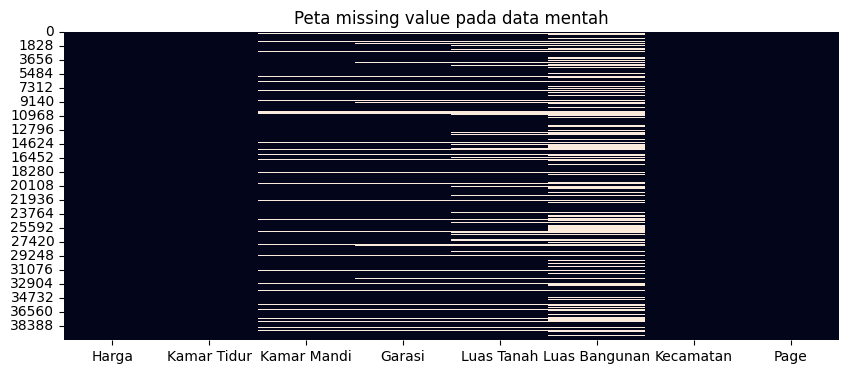

In [4]:
missing = df.isna().sum().sort_values(ascending=False)
kolom_utama = [c for c in df.columns if c != 'Page']
jumlah_duplikat_persis = int(df.duplicated().sum())
jumlah_duplikat_tanpa_page = int(df.duplicated(subset=kolom_utama).sum())

audit = pd.DataFrame({'Masalah': missing.index, 'Jumlah baris': missing.values})
print('Duplikat semua kolom:', jumlah_duplikat_persis)
print('Duplikat tanpa Page:', jumlah_duplikat_tanpa_page)
display(audit)
plt.figure(figsize=(10,4))
sns.heatmap(df.isna(), cbar=False)
plt.title('Peta missing value pada data mentah')
plt.show()

## 4. Cek pola isi kolom (penting pada dataset scraping)
Cari nilai aneh dan contoh kategori. Jangan membuang outlier hanya berdasarkan boxplot: rumah mewah bisa valid.

In [5]:
for kolom in ['Harga', 'Kamar Tidur', 'Kamar Mandi', 'Garasi', 'Luas Tanah', 'Luas Bangunan', 'Kecamatan']:
    print('\nKOLOM:', kolom)
    print('Jumlah variasi:', df[kolom].nunique(dropna=True))
    display(df[kolom].value_counts(dropna=False).head(8))

print('Harga Hubungi Agen:', df['Harga'].str.contains('Hubungi Agen', case=False, na=False).sum())
print('Kamar Tidur berisi LT/LB:', df['Kamar Tidur'].str.contains(r'^\s*(LT|LB)\s*:', flags=0, regex=True, na=False).sum())


KOLOM: Harga
Jumlah variasi: 2432


,count
Harga,
"1,2 Miliar",765
"1,5 Miliar",734
"2,5 Miliar",640
"1,3 Miliar",598
"3,5 Miliar",513
900 Juta,512
"1,1 Miliar",503
"1,6 Miliar",487



KOLOM: Kamar Tidur
Jumlah variasi: 1322


,count
Kamar Tidur,
3,13022
2,9593
4,6169
5,2641
1,1337
6,985
7,485
8,177



KOLOM: Kamar Mandi
Jumlah variasi: 688


...

,count
Luas Bangunan,
NaN,15602
LB : 40 m²,1134
LB : 100 m²,1035
LB : 36 m²,947
LB : 60 m²,927
LB : 200 m²,870
LB : 45 m²,854
LB : 90 m²,853



KOLOM: Kecamatan
Jumlah variasi: 38


,count
Kecamatan,
Cinere,8602
Sawangan,4650
Cimanggis,2978
Pancoran Mas,2386
Cilodong,1974
Beji,1893
Sukmajaya,1677
Depok I,1444


Harga Hubungi Agen: 41
Kamar Tidur berisi LT/LB: 4941


/tmp/ipykernel_1087/3273255001.py:7: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  print('Kamar Tidur berisi LT/LB:', df['Kamar Tidur'].str.contains(r'^\s*(LT|LB)\s*:', flags=0, regex=True, na=False).sum())


## 5. Mengubah target harga menjadi angka
Contoh `2,5 Miliar` menjadi `2.500.000.000`. Ini perlu sebelum perhitungan regresi. Harga yang tidak jelas (`Hubungi Agen`, harga per m²) tidak dipaksakan menjadi angka.

In [6]:
import re
SATUAN = {'ribu': 1_000, 'juta': 1_000_000, 'miliar': 1_000_000_000, 'triliun': 1_000_000_000_000}

def ubah_harga(nilai):
    if pd.isna(nilai):
        return np.nan
    cocok = re.fullmatch(r'\s*([0-9]+(?:[.,][0-9]+)?)\s*(Ribu|Juta|Miliar|Triliun)(?:\s+Total)?\s*',
                         str(nilai), flags=re.I)
    if not cocok:
        return np.nan
    angka = float(cocok.group(1).replace(',', '.'))
    return angka * SATUAN[cocok.group(2).lower()]

df['harga_rp'] = df['Harga'].map(ubah_harga)
df['kt_angka'] = pd.to_numeric(df['Kamar Tidur'], errors='coerce')
print('Harga tidak dapat diparsing:', df['harga_rp'].isna().sum())
print('Contoh hasil parsing:')
display(df[['Harga','harga_rp']].head(12))

Harga tidak dapat diparsing: 97
Contoh hasil parsing:


,Harga,harga_rp
0,"2,5 Miliar",2.500000e+09
1,385 Juta,3.850000e+08
2,385 Juta,3.850000e+08
3,385 Juta,3.850000e+08
4,385 Juta,3.850000e+08
5,385 Juta,3.850000e+08
6,950 Juta,9.500000e+08
7,525 Juta,5.250000e+08
8,"2,5 Miliar",2.500000e+09
9,"3,7 Miliar",3.700000e+09


## 6. Menentukan cakupan studi dan menangani listing berulang
Aturan dari eksperimen sebelumnya: harga Rp100 juta–Rp50 miliar dan 1–15 kamar tidur. Ini **keputusan cakupan penelitian** untuk membatasi listing yang dapat dianalisis, bukan bukti bahwa nilai di luar rentang pasti salah. Duplikat tanpa `Page` dibuang satu kali sebagai asumsi bahwa baris beratribut identik merupakan listing berulang; keputusan ini memiliki keterbatasan.

In [7]:
calon = df[df['harga_rp'].between(100_000_000, 50_000_000_000)
           & df['kt_angka'].between(1,15)].copy()
jumlah_sebelum = len(calon)
calon = calon.drop_duplicates(subset=kolom_utama, keep='first').reset_index(drop=True)
print('Total awal:', len(df))
print('Kandidat memenuhi cakupan:', jumlah_sebelum)
print('Setelah menghapus pola berulang:', len(calon))
calon.drop(columns='kt_angka').to_csv(DATA / 'rumah_scope.csv', index=False)
print('Disimpan:', DATA / 'rumah_scope.csv')

Total awal: 40200
Kandidat memenuhi cakupan: 34410
Setelah menghapus pola berulang: 26328
Disimpan: /content/drive/MyDrive/EarlyBird_Bengkod/data/rumah_scope.csv


## 7. Visualisasi harga dan 3 insight
Visualisasi dan insight di bawah dipakai untuk menjelaskan keputusan modelling. Analisis korelasi dihitung dari *teks luas tanah/bangunan* yang terbaca; sel yang salah posisi akan dipulihkan pada notebook 03.

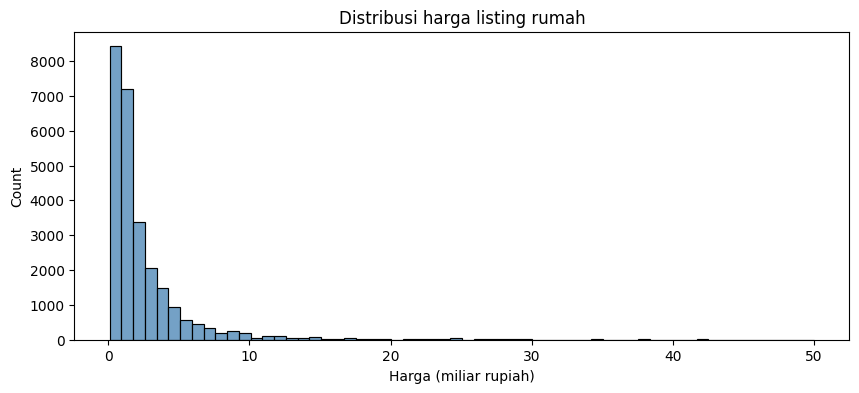

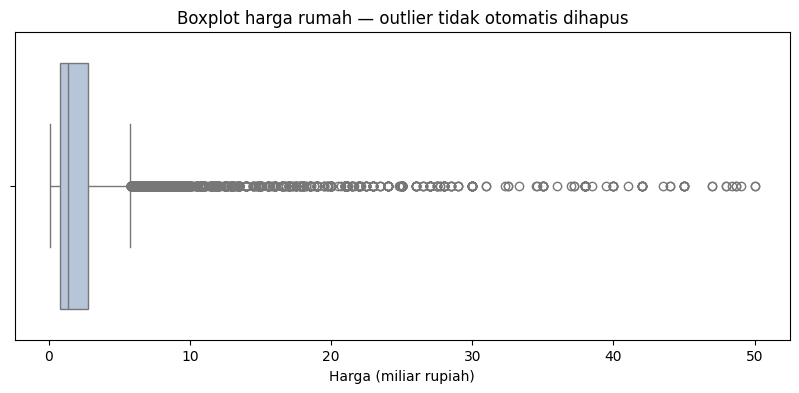

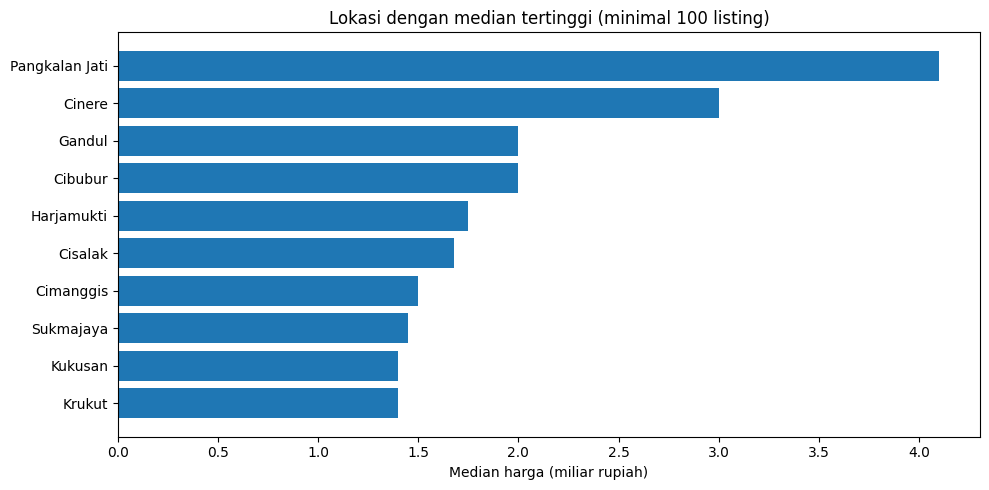

INSIGHT 1 — Harga sangat bervariasi: median = Rp1,400,000,000, P95 = Rp8,200,000,000.
KEPUTUSAN: gunakan metrik MAE, MAPE, R² dan pertimbangkan log-transform target.
INSIGHT 2 — Rentang median antar lokasi yang cukup datanya berbeda.
KEPUTUSAN: masukkan Kecamatan sebagai fitur kategorikal dengan One-Hot Encoding.
INSIGHT 3 — Teks luas, missing value, dan kolom bergeser mengurangi kualitas fitur.
KEPUTUSAN: pada preprocessing pulihkan LT/LB dan imputasi median dari data train saja.


In [8]:
from matplotlib.ticker import FuncFormatter

plt.figure(figsize=(10,4))
sns.histplot(calon['harga_rp'] / 1e9, bins=60, color='steelblue')
plt.title('Distribusi harga listing rumah')
plt.xlabel('Harga (miliar rupiah)')
plt.show()

plt.figure(figsize=(10,4))
sns.boxplot(x=calon['harga_rp'] / 1e9, color='lightsteelblue')
plt.title('Boxplot harga rumah — outlier tidak otomatis dihapus')
plt.xlabel('Harga (miliar rupiah)')
plt.show()

ringkas_lokasi = calon.groupby('Kecamatan')['harga_rp'].agg(['count','median'])
ringkas_lokasi = ringkas_lokasi[ringkas_lokasi['count'] >= 100].sort_values('median', ascending=False).head(10)
plt.figure(figsize=(10,5))
plt.barh(ringkas_lokasi.index[::-1], ringkas_lokasi['median'][::-1]/1e9)
plt.xlabel('Median harga (miliar rupiah)')
plt.title('Lokasi dengan median tertinggi (minimal 100 listing)')
plt.tight_layout();plt.show()

p50=calon['harga_rp'].median(); p95=calon['harga_rp'].quantile(0.95)
print('INSIGHT 1 — Harga sangat bervariasi: median = Rp{:,.0f}, P95 = Rp{:,.0f}.'.format(p50,p95))
print('KEPUTUSAN: gunakan metrik MAE, MAPE, R² dan pertimbangkan log-transform target.')
print('INSIGHT 2 — Rentang median antar lokasi yang cukup datanya berbeda.')
print('KEPUTUSAN: masukkan Kecamatan sebagai fitur kategorikal dengan One-Hot Encoding.')
print('INSIGHT 3 — Teks luas, missing value, dan kolom bergeser mengurangi kualitas fitur.')
print('KEPUTUSAN: pada preprocessing pulihkan LT/LB dan imputasi median dari data train saja.')

pd.DataFrame([{'Temuan':'Harga sangat bervariasi','Bukti':f'Median Rp{p50:,.0f}; P95 Rp{p95:,.0f}',
               'Tindakan':'Log target, MAE/MAPE/R2'},
              {'Temuan':'Lokasi berbeda','Bukti':f'{len(ringkas_lokasi)} lokasi punya >=100 listing',
               'Tindakan':'One Hot Encoding lokasi'},
              {'Temuan':'Kualitas fitur belum seragam','Bukti':f'Duplikat tanpa Page: {jumlah_duplikat_tanpa_page:,}',
               'Tindakan':'Parsing area, imputasi train-only'}]).to_csv(HASIL/'01_insight.csv',index=False)
audit.to_csv(HASIL/'01_missing.csv',index=False)

---

## BAGIAN 2 — DIRECT MODELING

Split yang tetap, parsing minimum, dan 5 model regresi sebagai baseline.

**Folder hasil dan dataset tetap memakai folder yang dibuat pada Bagian 1.** Tidak perlu mount Drive atau upload CSV ulang.

## 1. Baca data hasil EDA

In [9]:
sumber=DATA/'rumah_scope.csv'
if not sumber.exists():
    raise FileNotFoundError('Bagian 1 harus selesai dahulu')
df = pd.read_csv(sumber)
print('Ukuran:',df.shape)
display(df.head())

Ukuran: (26328, 9)


,Harga,Kamar Tidur,Kamar Mandi,Garasi,Luas Tanah,Luas Bangunan,Kecamatan,Page,harga_rp
0,"2,5 Miliar",4,3,10,LT : 438 m²,LB : 110 m²,Tapos,129,2.500000e+09
1,385 Juta,3,2,1,LT : 50 m²,LB : 60 m²,Pancoran Mas,129,3.850000e+08
2,385 Juta,3,2,1,LT : 50 m²,LB : 60 m²,Cipayung,129,3.850000e+08
3,385 Juta,3,2,1,LT : 50 m²,LB : 60 m²,Rangkapanjaya,129,3.850000e+08
4,950 Juta,2,1,1,LT : 87 m²,LB : 50 m²,Sawangan,129,9.500000e+08


## 2. Bagi data: train 70%, validasi 15%, test 15%
Untuk regresi, kita dapat menjaga persebaran harga secara kasar dengan **bin kuantil** (`qcut`). Berbeda dengan `stratify=y` untuk klasifikasi, harga merupakan angka kontinu. `random_state=42` agar pembagian bisa direproduksi.

In [10]:
from sklearn.model_selection import train_test_split

# Indeks dipakai agar pembagian ketiga subset konsisten.
indeks = np.arange(len(df))
bin_harga = pd.qcut(np.log1p(df['harga_rp']), q=10, labels=False, duplicates='drop')

train_val_idx, test_idx = train_test_split(indeks, test_size=0.15,
                                           random_state=42, stratify=bin_harga)
bin_sementara = pd.qcut(np.log1p(df.iloc[train_val_idx]['harga_rp']),
                        q=10, labels=False, duplicates='drop')
train_idx, val_idx = train_test_split(train_val_idx, test_size=0.15/0.85,
                                     random_state=42, stratify=bin_sementara)
train = df.iloc[train_idx].reset_index(drop=True)
validasi = df.iloc[val_idx].reset_index(drop=True)
test = df.iloc[test_idx].reset_index(drop=True)
assert len(train)+len(validasi)+len(test)==len(df)
for nama, data in [('train',train),('validasi',validasi),('test',test)]:
    data.to_csv(DATA / f'{nama}.csv', index=False)
    print(nama, len(data))
print('Test disimpan dan tidak dipakai memilih model.')

train 18428
validasi 3950
test 3950
Test disimpan dan tidak dipakai memilih model.


## 3. Konversi atribut sederhana
Seperti pelajaran encoding, tidak ada estimator regresi yang bisa langsung menerima teks seperti `LT : 90 m²`. Kita membaca nilai dari kolom aslinya saja. Data salah posisi **belum dipulihkan**.

In [11]:
import re

def angka_sederhana(nilai):
    if pd.isna(nilai):
        return np.nan
    teks = str(nilai).strip()
    # Contoh: '3' atau '2,0'. Teks lain tidak dipaksakan menjadi angka.
    if not re.fullmatch(r'\d+(?:[.,]\d+)?', teks):
        return np.nan
    return float(teks.replace(',', '.'))

def angka_luas(teks):
    if pd.isna(teks):
        return np.nan
    s = str(teks).strip()
    if ',' in s:  # '1.200,5' -> '1200.5'
        s = s.replace('.', '').replace(',', '.')
    elif re.fullmatch(r'\d{1,3}(?:\.\d{3})+', s):
        s = s.replace('.', '')
    try:
        return float(s)
    except ValueError:
        return np.nan

def ambil_luas_teks(teks, jenis):
    if pd.isna(teks):
        return np.nan
    cocok = re.search(r'\b' + jenis + r'\s*:\s*([0-9.,]+)', str(teks), flags=re.I)
    return angka_luas(cocok.group(1)) if cocok else np.nan

def dalam_rentang(nilai, minimum, maksimum):
    return float(nilai) if pd.notna(nilai) and minimum <= nilai <= maksimum else np.nan

def fitur_dasar(df):
    fitur = pd.DataFrame(index=df.index)
    fitur['kamar_tidur'] = df['Kamar Tidur'].map(angka_sederhana)
    fitur['kamar_mandi'] = df['Kamar Mandi'].map(angka_sederhana)
    fitur['garasi'] = df['Garasi'].map(angka_sederhana)
    fitur['luas_tanah'] = df['Luas Tanah'].map(lambda x: ambil_luas_teks(x, 'LT'))
    fitur['luas_bangunan'] = df['Luas Bangunan'].map(lambda x: ambil_luas_teks(x, 'LB'))
    for kolom, rendah, tinggi in [
        ('kamar_tidur', 1, 15), ('kamar_mandi', 0, 15), ('garasi', 0, 12),
        ('luas_tanah', 1, 20000), ('luas_bangunan', 1, 10000)
    ]:
        fitur[kolom] = fitur[kolom].map(lambda x: dalam_rentang(x, rendah, tinggi))
    fitur['lokasi'] = df['Kecamatan'].fillna('Tidak diketahui').astype(str).str.strip()
    fitur['lokasi'] = fitur['lokasi'].replace('', 'Tidak diketahui')
    return fitur

In [12]:
X_train = fitur_dasar(train)
X_valid = fitur_dasar(validasi)
y_train = train['harga_rp']
y_valid = validasi['harga_rp']
print('Jumlah missing value sebelum imputasi:')
display(X_train.isna().sum())

Jumlah missing value sebelum imputasi:


,0
kamar_tidur,0
kamar_mandi,895
garasi,6062
luas_tanah,6041
luas_bangunan,6043
lokasi,0


## 4. Lima algoritma dan Pipeline
Karena dataset tugas ini adalah **regresi**, gunakan `LinearRegression`, `Ridge`, `DecisionTreeRegressor`, `RandomForestRegressor`, `HistGradientBoostingRegressor` — bukan `LogisticRegression`, `DecisionTreeClassifier`, atau `accuracy`.

**Kenapa Pipeline?** `SimpleImputer`, `OneHotEncoder`, dan `StandardScaler` harus di-*fit* pada training saja. `TransformedTargetRegressor` mengerjakan log harga secara otomatis lalu mengembalikannya menjadi Rupiah.

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score
from sklearn.base import clone

SEED = 42
NUM_DASAR = ['kamar_tidur', 'kamar_mandi', 'garasi', 'luas_tanah', 'luas_bangunan']
NUM_LANJUT = NUM_DASAR + ['total_luas', 'rasio_lb_lt']
KATEGORI = ['lokasi']

# Model yang sama digunakan di Direct Modeling dan Modeling dengan Preprocessing.
DAFTAR_MODEL = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=10.0),
    'Decision Tree': DecisionTreeRegressor(max_depth=12, min_samples_leaf=8, random_state=SEED),
    'Random Forest': RandomForestRegressor(n_estimators=75, max_depth=16, min_samples_leaf=2,
                                          random_state=SEED, n_jobs=-1),
    'HistGradientBoosting': HistGradientBoostingRegressor(max_iter=110, learning_rate=0.07,
                                                          max_leaf_nodes=25, random_state=SEED)
}

def hitung_metrik(y_asli, y_pred):
    return {
        'MAE': mean_absolute_error(y_asli, y_pred),
        'MAPE (%)': mean_absolute_percentage_error(y_asli, y_pred) * 100,
        'R2': r2_score(y_asli, y_pred)
    }

def buat_pipeline(algoritma, fitur_numerik, selector=None):
    # Seluruh transformasi di-fit hanya saat model.fit(X_train, y_train).
    bagian_angka = Pipeline([
        ('imputer', SimpleImputer(strategy='median', add_indicator=True)),
        ('scaler', StandardScaler())
    ])
    bagian_kategori = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])
    preprocessing = ColumnTransformer([
        ('angka', bagian_angka, fitur_numerik),
        ('kategori', bagian_kategori, KATEGORI)
    ], remainder='drop')
    langkah = [('preprocessing', preprocessing)]
    if selector is not None:
        langkah.append(('seleksi', clone(selector)))
    langkah.append(('model', clone(algoritma)))
    pipeline = Pipeline(langkah)
    # Harga cenderung right-skewed. Pelatihan memakai log1p, hasil prediksi dikembalikan ke Rupiah.
    return TransformedTargetRegressor(regressor=pipeline, func=np.log1p,
                                      inverse_func=np.expm1, check_inverse=False)

In [14]:
NUMERIC_COLUMNS = NUM_DASAR
SELECTOR = None

hasil = []
for nama, algoritma in DAFTAR_MODEL.items():
    model = buat_pipeline(algoritma, NUMERIC_COLUMNS, selector=SELECTOR)
    model.fit(X_train, y_train)
    prediksi = model.predict(X_valid)
    skor = hitung_metrik(y_valid, prediksi)
    hasil.append({'Model': nama, **skor})
    print(f'{nama:22s} | MAE Rp{skor["MAE"]:,.0f} | MAPE {skor["MAPE (%)"]:.2f}% | R² {skor["R2"]:.4f}')

hasil_df = pd.DataFrame(hasil).sort_values('MAE').reset_index(drop=True)
display(hasil_df)

Linear Regression      | MAE Rp1,656,366,509 | MAPE 97.25% | R² -38.6975
Ridge Regression       | MAE Rp1,676,156,764 | MAPE 98.99% | R² -40.9324
Decision Tree          | MAE Rp923,611,526 | MAPE 37.00% | R² 0.4519
Random Forest          | MAE Rp852,329,597 | MAPE 34.48% | R² 0.4995
HistGradientBoosting   | MAE Rp873,588,073 | MAPE 35.18% | R² 0.5048


,Model,MAE,MAPE (%),R2
0,Random Forest,8.523296e+08,34.480433,0.499513
1,HistGradientBoosting,8.735881e+08,35.184505,0.504780
2,Decision Tree,9.236115e+08,37.003149,0.451918
3,Linear Regression,1.656367e+09,97.253705,-38.697505
4,Ridge Regression,1.676157e+09,98.986892,-40.932403


In [15]:
hasil_df.to_csv(HASIL/'02_direct.csv', index=False)
print('Hasil tersimpan di:', HASIL/'02_direct.csv')

Hasil tersimpan di: /content/drive/MyDrive/EarlyBird_Bengkod/hasil/02_direct.csv


## Interpretasi
**MAE:** rata-rata selisih Rupiah. **MAPE:** rata-rata persentase kesalahan harga. **R²:** seberapa besar variasi harga dijelaskan model, bukan akurasi persentase.

**Berikutnya:** **Bagian 3** akan memakai **pembagian baris yang sama** agar perbandingan adil.

---

## BAGIAN 3 — PREPROCESSING & MODELING ULANG

Pemulihan LT/LB, imputasi dan encoding dalam Pipeline, lalu lima model yang sama.

**Folder hasil dan dataset tetap memakai folder yang dibuat pada Bagian 1.** Tidak perlu mount Drive atau upload CSV ulang.

In [16]:
file_train = DATA / 'train.csv'
file_valid = DATA / 'validasi.csv'
file_test = DATA / 'test.csv'
for p in [file_train, file_valid, file_test]:
    if not p.exists():
        raise FileNotFoundError(f'{p.name} belum dibuat. Selesaikan Bagian 2 dahulu.')
train = pd.read_csv(file_train)
validasi = pd.read_csv(file_valid)
test = pd.read_csv(file_test)
print('Train:', train.shape, '| Validasi:', validasi.shape, '| Test:', test.shape)

Train: (18428, 9) | Validasi: (3950, 9) | Test: (3950, 9)


## 1. Memeriksa contoh kolom yang bergeser
Kolom `Kamar Mandi` atau `Garasi` kadang berisi `LT:` dan `LB:`. Inilah alasan data cleaning perlu mengikuti EDA, bukan sekadar `dropna()`.

In [17]:
print('Contoh isi kolom yang perlu diperiksa:')
contoh = train[train['Kamar Mandi'].fillna('').str.contains('LT|LB',case=False,regex=True)]
display(contoh[['Kamar Tidur','Kamar Mandi','Garasi','Luas Tanah','Luas Bangunan']].head())

Contoh isi kolom yang perlu diperiksa:


,Kamar Tidur,Kamar Mandi,Garasi,Luas Tanah,Luas Bangunan
1,1,LT:67 m²,LB:150 m²,NaN,NaN
2,2,LT:100 m²,LB:250 m²,NaN,NaN
18,2,LT:101 m²,LB:98 m²,NaN,NaN
44,2,LT:60 m²,LB:112 m²,NaN,NaN
53,2,LT:78 m²,LB:84 m²,NaN,NaN


## 2. Konversi dan pemulihan LT/LB

In [18]:
# Memulihkan LT/LB yang tertulis pada kolom yang keliru.
# Tidak mengubah target Harga; hanya atribut fisik.
def ambil_luas_dari_baris(baris, jenis):
    urutan = (['Luas Tanah', 'Kamar Mandi', 'Garasi', 'Kamar Tidur', 'Luas Bangunan']
              if jenis == 'LT' else
              ['Luas Bangunan', 'Garasi', 'Kamar Mandi', 'Luas Tanah', 'Kamar Tidur'])
    for kolom in urutan:
        nilai = ambil_luas_teks(baris[kolom], jenis)
        if pd.notna(nilai):
            return nilai
    return np.nan

def fitur_bersih(df):
    fitur = fitur_dasar(df)
    fitur['luas_tanah'] = df.apply(lambda baris: ambil_luas_dari_baris(baris, 'LT'), axis=1)
    fitur['luas_bangunan'] = df.apply(lambda baris: ambil_luas_dari_baris(baris, 'LB'), axis=1)
    fitur['luas_tanah'] = fitur['luas_tanah'].map(lambda x: dalam_rentang(x, 1, 20000))
    fitur['luas_bangunan'] = fitur['luas_bangunan'].map(lambda x: dalam_rentang(x, 1, 10000))
    fitur['total_luas'] = fitur['luas_tanah'] + fitur['luas_bangunan']
    fitur['rasio_lb_lt'] = (fitur['luas_bangunan'] / fitur['luas_tanah']).clip(upper=20)
    fitur = fitur.replace([np.inf, -np.inf], np.nan)
    return fitur

In [19]:
NUM_DASAR = ['kamar_tidur','kamar_mandi','garasi','luas_tanah','luas_bangunan']
X_train = fitur_bersih(train)
X_valid = fitur_bersih(validasi)
X_test = fitur_bersih(test)
y_train = train['harga_rp']; y_valid=validasi['harga_rp']; y_test=test['harga_rp']

print('Missing value numerik setelah parsing, sebelum imputasi:')
display(X_train[NUM_DASAR].isna().sum())
print('Contoh data bersih:')
display(X_train.head())

# Simpan hasil parsing (belum imputasi/scaling). Imputer dan scaler fit pada train di Pipeline.
for nama, X, y in [('train',X_train,y_train),('validasi',X_valid,y_valid),('test',X_test,y_test)]:
    data_simpan = X.copy()
    data_simpan['harga_rp'] = y.to_numpy()
    data_simpan.to_csv(DATA / f'bersih_{nama}.csv', index=False)
print('Tiga file bersih_*.csv tersimpan.')

Missing value numerik setelah parsing, sebelum imputasi:


,0
kamar_tidur,0
kamar_mandi,895
garasi,6062
luas_tanah,694
luas_bangunan,15


Contoh data bersih:


,kamar_tidur,kamar_mandi,garasi,luas_tanah,luas_bangunan,lokasi,total_luas,rasio_lb_lt
0,3.0,2.0,1.0,81.0,77.0,Cimanggis,158.0,0.950617
1,1.0,NaN,NaN,67.0,150.0,Cimanggis,217.0,2.238806
2,2.0,NaN,NaN,100.0,250.0,Cinere,350.0,2.500000
3,2.0,1.0,1.0,93.0,55.0,Cimanggis,148.0,0.591398
4,5.0,4.0,2.0,524.0,500.0,Cinere,1024.0,0.954198


Tiga file bersih_*.csv tersimpan.


## 3. Uji perbedaan kualitas fitur
Contoh: berapa LT/LB yang berhasil dipulihkan dari kolom lain? Ini bahan presentasi.

In [20]:
X_dasar_train = fitur_dasar(train)
for nama in ['luas_tanah','luas_bangunan']:
    pulih = X_dasar_train[nama].isna() & X_train[nama].notna()
    print(nama, 'nilai berhasil dipulihkan:', int(pulih.sum()))

# Hasil imputasi/scaling tidak disimpan sebagai CSV terpisah agar transformasinya
# tetap melekat pada pipeline yang kelak digunakan untuk prediksi data baru.

luas_tanah nilai berhasil dipulihkan: 5347
luas_bangunan nilai berhasil dipulihkan: 6028


## 4. Modeling ulang lima algoritma
Kita tetap memakai model yang sama dengan Bagian 2, agar perbandingan mengukur manfaat preprocessing. Perubahan input fitur adalah perbedaan yang disengaja.

In [21]:
NUMERIC_COLUMNS = NUM_LANJUT
SELECTOR = None

hasil = []
for nama, algoritma in DAFTAR_MODEL.items():
    model = buat_pipeline(algoritma, NUMERIC_COLUMNS, selector=SELECTOR)
    model.fit(X_train, y_train)
    prediksi = model.predict(X_valid)
    skor = hitung_metrik(y_valid, prediksi)
    hasil.append({'Model': nama, **skor})
    print(f'{nama:22s} | MAE Rp{skor["MAE"]:,.0f} | MAPE {skor["MAPE (%)"]:.2f}% | R² {skor["R2"]:.4f}')

hasil_df = pd.DataFrame(hasil).sort_values('MAE').reset_index(drop=True)
display(hasil_df)

Linear Regression      | MAE Rp57,412,236,472 | MAPE 366.14% | R² -465944.3408
Ridge Regression       | MAE Rp57,380,496,118 | MAPE 366.59% | R² -465037.9200
Decision Tree          | MAE Rp709,206,131 | MAPE 28.68% | R² 0.7186
Random Forest          | MAE Rp608,879,875 | MAPE 24.82% | R² 0.7799
HistGradientBoosting   | MAE Rp676,022,311 | MAPE 26.35% | R² 0.7623


,Model,MAE,MAPE (%),R2
0,Random Forest,6.088799e+08,24.824873,0.779905
1,HistGradientBoosting,6.760223e+08,26.346144,0.762325
2,Decision Tree,7.092061e+08,28.681120,0.718627
3,Ridge Regression,5.738050e+10,366.588644,-465037.920006
4,Linear Regression,5.741224e+10,366.144013,-465944.340771


## 5. Perbandingan terhadap Direct Modeling

,Model,MAE_direct,MAE_bersih,Penurunan MAE (%)
0,Random Forest,8.523296e+08,6.088799e+08,28.562861
1,HistGradientBoosting,8.735881e+08,6.760223e+08,22.615437
2,Decision Tree,9.236115e+08,7.092061e+08,23.213807
4,Ridge Regression,1.676157e+09,5.738050e+10,-3323.337086
3,Linear Regression,1.656367e+09,5.741224e+10,-3366.155356


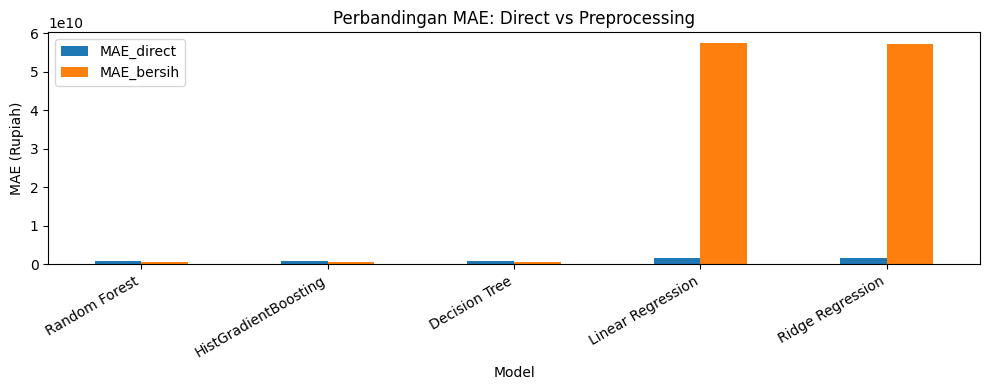

In [22]:
hasil_df.to_csv(HASIL/'03_preprocessing.csv',index=False)
direct = pd.read_csv(HASIL/'02_direct.csv')
banding = direct[['Model','MAE']].merge(hasil_df[['Model','MAE']],on='Model',suffixes=('_direct','_bersih'))
banding['Penurunan MAE (%)'] = (banding['MAE_direct']-banding['MAE_bersih'])/banding['MAE_direct']*100
display(banding.sort_values('MAE_bersih'))

banding.set_index('Model')[['MAE_direct','MAE_bersih']].plot(kind='bar',figsize=(10,4))
plt.title('Perbandingan MAE: Direct vs Preprocessing')
plt.ylabel('MAE (Rupiah)');plt.xticks(rotation=30,ha='right');plt.tight_layout();plt.show()

**Berikutnya:** **Bagian 4**. Perhatikan, mempelajari nilai median dan parameter scaling selalu dilakukan pada data train melalui `Pipeline`. Dataset test belum digunakan untuk pengukuran performa.

---

## BAGIAN 4 — FEATURE SELECTION

Korelasi numerik dan SelectKBest(f_regression) di dalam Pipeline.

**Folder hasil dan dataset tetap memakai folder yang dibuat pada Bagian 1.** Tidak perlu mount Drive atau upload CSV ulang.

In [23]:
files_clean = [DATA / f'bersih_{jenis}.csv' for jenis in ['train','validasi','test']]
for p in files_clean:
    if not p.exists():
        raise FileNotFoundError(f'{p.name} belum tersedia. Selesaikan Bagian 3 terlebih dahulu.')
train = pd.read_csv(files_clean[0])
validasi = pd.read_csv(files_clean[1])
test = pd.read_csv(files_clean[2])
X_train = train.drop(columns=['harga_rp'])
y_train = train['harga_rp']
X_valid = validasi.drop(columns=['harga_rp'])
y_valid = validasi['harga_rp']
X_test = test.drop(columns=['harga_rp'])
y_test = test['harga_rp']
print('Train:', len(train), 'Validasi:', len(validasi), 'Test:', len(test))

Train: 18428 Validasi: 3950 Test: 3950


## 1. Korelasi numerik terhadap Harga (training saja)

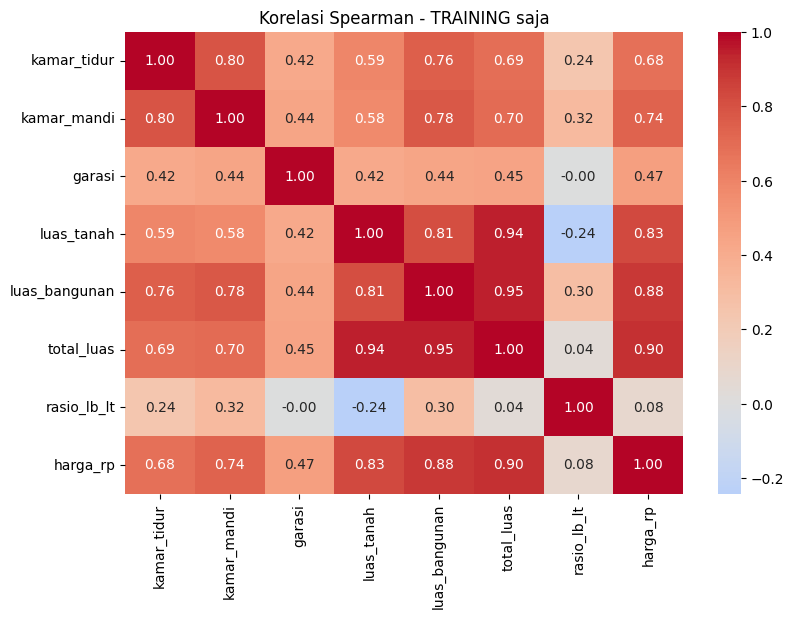

,harga_rp
harga_rp,1.000000
total_luas,0.903007
luas_bangunan,0.884185
luas_tanah,0.831908
kamar_mandi,0.738133
kamar_tidur,0.682052
garasi,0.471111
rasio_lb_lt,0.083102


In [24]:
kolom_angka=['kamar_tidur','kamar_mandi','garasi','luas_tanah','luas_bangunan','total_luas','rasio_lb_lt']
korelasi=train[kolom_angka+['harga_rp']].corr(method='spearman')
plt.figure(figsize=(9,6))
sns.heatmap(korelasi, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Korelasi Spearman - TRAINING saja')
plt.show()
display(korelasi['harga_rp'].sort_values(ascending=False))

## 2. Pilih fitur dengan `SelectKBest(f_regression)`
Metode ini melihat hubungan tiap fitur numerik terhadap target. Pemilihan dilakukan **di dalam Pipeline** agar pada cross-validation nanti pemilihan fitur diulang pada fold training, bukan menggunakan label fold validasi. Nilai `k=15` adalah pilihan eksperimen untuk tugas, bukan hasil optimasi.

In [25]:
from sklearn.feature_selection import SelectKBest, f_regression
NUMERIC_COLUMNS=NUM_LANJUT
SELECTOR=SelectKBest(score_func=f_regression, k=15)

hasil = []
for nama, algoritma in DAFTAR_MODEL.items():
    model = buat_pipeline(algoritma, NUMERIC_COLUMNS, selector=SELECTOR)
    model.fit(X_train, y_train)
    prediksi = model.predict(X_valid)
    skor = hitung_metrik(y_valid, prediksi)
    hasil.append({'Model': nama, **skor})
    print(f'{nama:22s} | MAE Rp{skor["MAE"]:,.0f} | MAPE {skor["MAPE (%)"]:.2f}% | R² {skor["R2"]:.4f}')

hasil_df = pd.DataFrame(hasil).sort_values('MAE').reset_index(drop=True)
display(hasil_df)

Linear Regression      | MAE Rp129,356,720,191 | MAPE 886.35% | R² -2443162.8735
Ridge Regression       | MAE Rp129,389,161,089 | MAPE 887.53% | R² -2444096.5522
Decision Tree          | MAE Rp712,014,988 | MAPE 28.90% | R² 0.7247
Random Forest          | MAE Rp616,924,256 | MAPE 25.49% | R² 0.7746
HistGradientBoosting   | MAE Rp701,474,891 | MAPE 27.70% | R² 0.7416


,Model,MAE,MAPE (%),R2
0,Random Forest,6.169243e+08,25.490809,7.746348e-01
1,HistGradientBoosting,7.014749e+08,27.696859,7.416290e-01
2,Decision Tree,7.120150e+08,28.900285,7.247144e-01
3,Linear Regression,1.293567e+11,886.351755,-2.443163e+06
4,Ridge Regression,1.293892e+11,887.525540,-2.444097e+06


## 3. Lihat fitur yang terpilih dan bandingkan

In [26]:
hasil_df.to_csv(HASIL/'04_feature_selection.csv',index=False)
model_contoh=buat_pipeline(DAFTAR_MODEL['Random Forest'], NUM_LANJUT, selector=SELECTOR)
model_contoh.fit(X_train,y_train)
langkah=model_contoh.regressor_
nama_fitur=langkah.named_steps['preprocessing'].get_feature_names_out()
mask=langkah.named_steps['seleksi'].get_support()
print('Total fitur setelah OHE:', len(nama_fitur))
print('Fitur yang dipilih:', len(nama_fitur[mask]))
print(nama_fitur[mask].tolist())

sebelum = pd.read_csv(HASIL/'03_preprocessing.csv')
perbandingan=sebelum[['Model','MAE']].merge(hasil_df[['Model','MAE']], on='Model',
                                           suffixes=('_semua_fitur','_seleksi'))
display(perbandingan.sort_values('MAE_seleksi'))

Total fitur setelah OHE: 50
Fitur yang dipilih: 15
['angka__kamar_tidur', 'angka__kamar_mandi', 'angka__garasi', 'angka__luas_tanah', 'angka__luas_bangunan', 'angka__total_luas', 'angka__missingindicator_luas_tanah', 'angka__missingindicator_total_luas', 'angka__missingindicator_rasio_lb_lt', 'kategori__lokasi_Cilodong', 'kategori__lokasi_Cinere', 'kategori__lokasi_Cipayung', 'kategori__lokasi_Citayam', 'kategori__lokasi_Pangkalan Jati', 'kategori__lokasi_Sawangan']


,Model,MAE_semua_fitur,MAE_seleksi
0,Random Forest,6.088799e+08,6.169243e+08
1,HistGradientBoosting,6.760223e+08,7.014749e+08
2,Decision Tree,7.092061e+08,7.120150e+08
4,Linear Regression,5.741224e+10,1.293567e+11
3,Ridge Regression,5.738050e+10,1.293892e+11


**Catatan ilmiah:** Feature selection tidak wajib meningkatkan MAE. Jika MAE lebih besar, tidak berarti kode salah. Kita tetap membandingkannya dengan metode semua fitur menggunakan validation yang sama. Selanjutnya `05_Tuning_Evaluasi_Final.ipynb`.

---

## BAGIAN 5 — GRID SEARCH, EVALUASI FINAL & MODEL

Tuning dengan KFold pada train, perbandingan validation, test sekali, dan simpan model.

**Folder hasil dan dataset tetap memakai folder yang dibuat pada Bagian 1.** Tidak perlu mount Drive atau upload CSV ulang.

In [27]:
files_clean = [DATA / f'bersih_{jenis}.csv' for jenis in ['train','validasi','test']]
for p in files_clean:
    if not p.exists():
        raise FileNotFoundError(f'{p.name} belum tersedia. Selesaikan Bagian 3 terlebih dahulu.')
train = pd.read_csv(files_clean[0])
validasi = pd.read_csv(files_clean[1])
test = pd.read_csv(files_clean[2])
X_train = train.drop(columns=['harga_rp'])
y_train = train['harga_rp']
X_valid = validasi.drop(columns=['harga_rp'])
y_valid = validasi['harga_rp']
X_test = test.drop(columns=['harga_rp'])
y_test = test['harga_rp']
print('Train:', len(train), 'Validasi:', len(validasi), 'Test:', len(test))

Train: 18428 Validasi: 3950 Test: 3950


## 1. Pilih kandidat dari preprocessing vs feature selection (validation)

In [28]:
hasil_pre = pd.read_csv(HASIL/'03_preprocessing.csv')
hasil_sel = pd.read_csv(HASIL/'04_feature_selection.csv')
hasil_pre['Tahap']='Preprocessing'
hasil_sel['Tahap']='Feature Selection'
gabungan=pd.concat([hasil_pre,hasil_sel],ignore_index=True)
display(gabungan.sort_values('MAE'))
terbaik=gabungan.sort_values('MAE').iloc[0]
nama_model=terbaik['Model']
pakai_seleksi=terbaik['Tahap']=='Feature Selection'
print('Kandidat untuk tuning:',nama_model,'| Tahap:',terbaik['Tahap'])

,Model,MAE,MAPE (%),R2,Tahap
0,Random Forest,6.088799e+08,24.824873,7.799049e-01,Preprocessing
5,Random Forest,6.169243e+08,25.490809,7.746348e-01,Feature Selection
1,HistGradientBoosting,6.760223e+08,26.346144,7.623246e-01,Preprocessing
6,HistGradientBoosting,7.014749e+08,27.696859,7.416290e-01,Feature Selection
2,Decision Tree,7.092061e+08,28.681120,7.186272e-01,Preprocessing
7,Decision Tree,7.120150e+08,28.900285,7.247144e-01,Feature Selection
3,Ridge Regression,5.738050e+10,366.588644,-4.650379e+05,Preprocessing
4,Linear Regression,5.741224e+10,366.144013,-4.659443e+05,Preprocessing
8,Linear Regression,1.293567e+11,886.351755,-2.443163e+06,Feature Selection
9,Ridge Regression,1.293892e+11,887.525540,-2.444097e+06,Feature Selection


Kandidat untuk tuning: Random Forest | Tahap: Preprocessing


## 2. GridSearchCV dengan 3-fold (train saja)
Seperti contoh di kelas, parameternya dicoba dalam sebuah grid. Kita memilih grid kecil agar cukup praktis di Colab. `scoring='neg_mean_absolute_error'` digunakan karena ini **regresi**, bukan classification accuracy.

In [29]:
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.metrics import mean_absolute_error

seleksi=SelectKBest(f_regression,k=15) if pakai_seleksi else None
model_awal=buat_pipeline(DAFTAR_MODEL[nama_model], NUM_LANJUT, selector=seleksi)

# Grid sesuai jenis model yang terpilih.
GRID={
 'Linear Regression': {'regressor__model__fit_intercept':[True,False]},
 'Ridge Regression': {'regressor__model__alpha':[1.0,10.0,100.0]},
 'Decision Tree': {'regressor__model__max_depth':[8,12,18],
                   'regressor__model__min_samples_leaf':[3,8]},
 'Random Forest': {'regressor__model__n_estimators':[60,100],
                   'regressor__model__max_depth':[12,18],
                   'regressor__model__min_samples_leaf':[2,4]},
 'HistGradientBoosting': {'regressor__model__max_iter':[80,120],
                          'regressor__model__learning_rate':[0.05,0.10]}
}

cv=KFold(n_splits=3,shuffle=True,random_state=42)
grid_search=GridSearchCV(model_awal,GRID[nama_model],scoring='neg_mean_absolute_error',
                         cv=cv,n_jobs=1,refit=True,verbose=1,error_score='raise')
grid_search.fit(X_train,y_train)
print('Parameter terbaik:',grid_search.best_params_)
print('MAE CV rata-rata: Rp{:,.0f}'.format(-grid_search.best_score_))

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Parameter terbaik: {'regressor__model__max_depth': 18, 'regressor__model__min_samples_leaf': 2, 'regressor__model__n_estimators': 100}
MAE CV rata-rata: Rp617,988,221


## 3. Bandingkan kandidat tuning pada validation
Model tuning tidak otomatis lebih baik; bandingkan dengan kandidat yang tidak dituning, dan pilih berdasar MAE validation.

In [30]:
pred_valid_tuned=grid_search.best_estimator_.predict(X_valid)
skor_tuned=hitung_metrik(y_valid,pred_valid_tuned)
print('Tuning pada validation:',skor_tuned)
print('Sebelum tuning (MAE): Rp{:,.0f}'.format(terbaik['MAE']))

if skor_tuned['MAE'] < terbaik['MAE']:
    final_model=grid_search.best_estimator_
    tahap_final='Tuning'
else:
    final_model=buat_pipeline(DAFTAR_MODEL[nama_model], NUM_LANJUT, selector=seleksi)
    final_model.fit(X_train,y_train)
    tahap_final=terbaik['Tahap']
print('Model final:',nama_model,'| Tahap:',tahap_final)

# Tampilkan hasil per tahap untuk dokumentasi tugas.
rekap = pd.concat([
    pd.read_csv(HASIL/'02_direct.csv').assign(Tahap='Direct Modeling'),
    hasil_pre,
    hasil_sel,
    pd.DataFrame([{'Model':nama_model,'Tahap':'Tuning',**skor_tuned}])
], ignore_index=True)
rekap.to_csv(HASIL/'05_rekap_semua_tahap.csv', index=False)
display(rekap.sort_values('MAE'))

skor_final_valid = skor_tuned if tahap_final=='Tuning' else {
    'MAE':float(terbaik['MAE']),
    'MAPE (%)':float(terbaik['MAPE (%)']),
    'R2':float(terbaik['R2'])
}
print('MAE model TERPILIH pada validation: Rp{:,.0f}'.format(skor_final_valid['MAE']))

Tuning pada validation: {'MAE': 596913363.0230943, 'MAPE (%)': 24.390315589100734, 'R2': 0.7831560623779594}
Sebelum tuning (MAE): Rp608,879,875
Model final: Random Forest | Tahap: Tuning


,Model,MAE,MAPE (%),R2,Tahap
15,Random Forest,5.969134e+08,24.390316,7.831561e-01,Tuning
5,Random Forest,6.088799e+08,24.824873,7.799049e-01,Preprocessing
10,Random Forest,6.169243e+08,25.490809,7.746348e-01,Feature Selection
6,HistGradientBoosting,6.760223e+08,26.346144,7.623246e-01,Preprocessing
11,HistGradientBoosting,7.014749e+08,27.696859,7.416290e-01,Feature Selection
7,Decision Tree,7.092061e+08,28.681120,7.186272e-01,Preprocessing
12,Decision Tree,7.120150e+08,28.900285,7.247144e-01,Feature Selection
0,Random Forest,8.523296e+08,34.480433,4.995130e-01,Direct Modeling
1,HistGradientBoosting,8.735881e+08,35.184505,5.047801e-01,Direct Modeling
2,Decision Tree,9.236115e+08,37.003149,4.519180e-01,Direct Modeling


MAE model TERPILIH pada validation: Rp596,913,363


## 4. Evaluasi **test** sekali setelah final dipilih
Jangan gunakan hasil test untuk memilih parameter, mengubah fitur, atau memilih model; test hanya untuk pengukuran terakhir.

=== TEST SET (TERAKHIR) ===
MAE: 571,432,529.0167
MAPE (%): 23.8102
R2: 0.8427


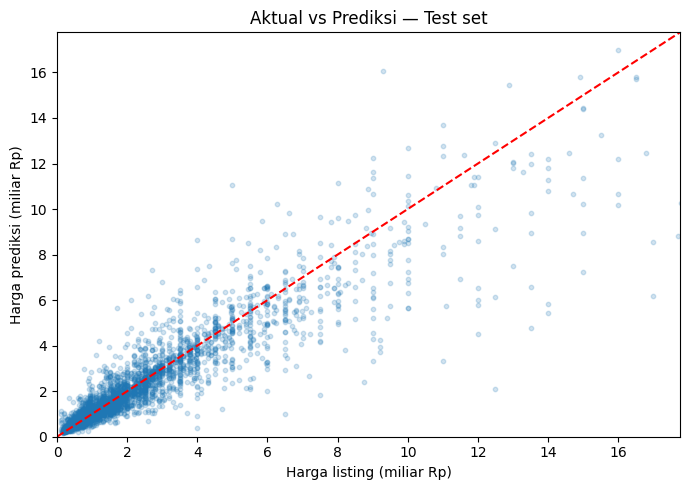

In [31]:
pred_test=final_model.predict(X_test)
skor_test=hitung_metrik(y_test,pred_test)
print('=== TEST SET (TERAKHIR) ===')
for nama, nilai in skor_test.items():
    print(f'{nama}: {nilai:,.4f}')

plt.figure(figsize=(7,5))
plt.scatter(y_test/1e9, pred_test/1e9, alpha=0.2, s=10)
limit=np.quantile(np.r_[y_test.values,pred_test],0.99)/1e9
plt.plot([0,limit],[0,limit],'r--')
plt.xlim(0,limit);plt.ylim(0,limit)
plt.xlabel('Harga listing (miliar Rp)')
plt.ylabel('Harga prediksi (miliar Rp)')
plt.title('Aktual vs Prediksi — Test set')
plt.tight_layout();plt.show()

## 5. Simpan model dan ringkasan hasil
`joblib` memuat pipeline *beserta* imputasi, encoding, scaling, dan seleksi jika dipilih. Ini mencegah perbedaan preprocessing saat prediksi. Nama file dibuat **berbeda** agar tidak menimpa model Streamlit sebelumnya.

In [32]:
import joblib, json
artifact={
    'model':final_model,
    'lokasi': sorted(X_train['lokasi'].dropna().unique().tolist()),
    'model_name':nama_model,
    'stage':tahap_final,
    'metrik_test': {'MAE_Rp':float(skor_test['MAE']),
                    'MAPE_Pct':float(skor_test['MAPE (%)']),
                    'R2':float(skor_test['R2'])},
    'batas_studi':'harga Rp100 juta–Rp50 miliar; kamar tidur 1–15'
}
joblib.dump(artifact, HASIL/'model_versi_bengkod_rapi.joblib',compress=3)
with open(HASIL/'05_metrik_final.json','w',encoding='utf8') as f:
    json.dump({k:v for k,v in artifact.items() if k!='model'},f,ensure_ascii=False,indent=2)
print('Model tersimpan di:', HASIL/'model_versi_bengkod_rapi.joblib')

Model tersimpan di: /content/drive/MyDrive/EarlyBird_Bengkod/hasil/model_versi_bengkod_rapi.joblib


---

## BAGIAN 6 — PERSIAPAN DEPLOYMENT STREAMLIT

Validasi model terlatih, smoke test, dan ZIP untuk memperbarui model dalam GitHub.

## 2. Audit kompatibilitas dengan `app.py` yang sudah ada

Aplikasi membutuhkan dictionary berisi `model`, `lokasi`, `model_name`, `stage`, dan `metrik_test` dengan subkunci `MAE_Rp`. Input model adalah variabel hasil preprocessing, bukan teks mentah CSV.


In [33]:
import json, shutil, zipfile, joblib, sklearn
from IPython.display import display

ROOT = PROYEK  # Pakai folder proyek yang sama dengan Bagian 1–5.
SUMBER = HASIL / 'model_versi_bengkod_rapi.joblib'
if not SUMBER.is_file():
    raise FileNotFoundError('Model belum ditemukan. Pastikan Bagian 5 selesai: ' + str(SUMBER))
artifact = joblib.load(SUMBER)
print('Model ditemukan:', SUMBER)
print('Versi scikit-learn:', sklearn.__version__)


Model ditemukan: /content/drive/MyDrive/EarlyBird_Bengkod/hasil/model_versi_bengkod_rapi.joblib
Versi scikit-learn: 1.6.1


In [34]:
required = {'model','lokasi','model_name','stage','metrik_test'}
missing = required - set(artifact)
if missing:
    raise KeyError(f'Artifact tidak kompatibel, kunci hilang: {sorted(missing)}')
if 'MAE_Rp' not in artifact['metrik_test']:
    raise KeyError("metrik_test harus memiliki 'MAE_Rp'")
if not artifact['lokasi']:
    raise ValueError('Daftar lokasi kosong')
if not np.isfinite(float(artifact['metrik_test']['MAE_Rp'])):
    raise ValueError('Nilai MAE test tidak valid')

print('Algoritma terpilih:', artifact['model_name'])
print('Tahap model:', artifact['stage'])
for k, v in artifact['metrik_test'].items():
    print(f'Test {k}: {v:,.4f}')
print('Jumlah lokasi:', len(artifact['lokasi']))


Algoritma terpilih: Random Forest
Tahap model: Tuning
Test MAE_Rp: 571,432,529.0167
Test MAPE_Pct: 23.8102
Test R2: 0.8427
Jumlah lokasi: 37


## 3. Smoke test dengan format input Streamlit

Tes ini hanya mengecek apakah model bisa dipanggil tanpa error. Angka hasil **bukan bukti akurasi**. Pengukuran akurasi tetap berdasarkan data test pada Bagian 5.


In [35]:
# Contoh yang sama dengan input standar Streamlit.
lokasi_uji = 'Babadan' if 'Babadan' in artifact['lokasi'] else artifact['lokasi'][0]
lt, lb = 90.0, 70.0
contoh = pd.DataFrame([{
    'kamar_tidur': 3.0,
    'kamar_mandi': 2.0,
    'garasi': 1.0,
    'luas_tanah': lt,
    'luas_bangunan': lb,
    'total_luas': lt + lb,
    'rasio_lb_lt': min(lb / lt, 20.0),
    'lokasi': lokasi_uji,
}])

prediksi = float(artifact['model'].predict(contoh)[0])
if not np.isfinite(prediksi) or prediksi <= 0:
    raise ValueError('Smoke test gagal: prediksi harus angka positif dan finite')
print('Input:')
display(contoh)
print(f'Hasil prediksi smoke test: Rp {prediksi:,.0f}'.replace(',','.'))


Input:


,kamar_tidur,kamar_mandi,garasi,luas_tanah,luas_bangunan,total_luas,rasio_lb_lt,lokasi
0,3.0,2.0,1.0,90.0,70.0,160.0,0.777778,Babadan


Hasil prediksi smoke test: Rp 931.792.910


In [36]:
OUTPUT = ROOT / 'deployment_baru'
OUTPUT.mkdir(parents=True, exist_ok=True)
MODEL_DEPLOY = OUTPUT / 'house_price_model.joblib'
shutil.copy2(SUMBER, MODEL_DEPLOY)

# Pastikan model benar-benar bisa dimuat ulang dari file yang akan diunggah.
loaded = joblib.load(MODEL_DEPLOY)
ulang = float(loaded['model'].predict(contoh)[0])
assert np.isclose(prediksi, ulang, rtol=0, atol=0.01), 'Prediksi berubah setelah disimpan ulang!'

requirements = '\n'.join([
    'streamlit>=1.35,<2',
    f'scikit-learn=={sklearn.__version__}',
    'pandas>=2,<3',
    'numpy>=1.26,<3',
    'joblib>=1.3,<2',
]) + '\n'
(OUTPUT / 'requirements.txt').write_text(requirements, encoding='utf-8')

petunjuk = """UPDATE MODEL EARLY BIRD KE STREAMLIT

1. Pastikan model ini dihasilkan oleh Bagian 1–5 yang dijalankan pada DATASET PENUH.
2. Buka repository: https://github.com/Michael152005/earlybird-house-price-prediction
3. Pada root repository, pilih house_price_model.joblib.
4. Klik ikon edit/upload pengganti sesuai UI GitHub, atau gunakan git untuk mengganti file.
   Jika situs GitHub tidak menawarkan tombol edit untuk file biner, gunakan git lokal
   atau hapus file lama lalu upload file baru dengan nama yang sama.
5. Ganti requirements.txt di root dengan file dalam paket ini (versi sklearn dipin).
6. Simpan/commit perubahan. Streamlit Cloud biasanya mendeteksi commit dan redeploy.
7. Buka aplikasi, uji skenario Babadan (KT3/KM2/G1/LT90/LB70).
8. Cocokkan harga dan nama model dengan hasil uji pada Bagian 6.

PENTING: Jangan mengganti app.py kecuali sudah diverifikasi perlu.
Prediksi contoh dapat berbeda dari model lama: model baru memakai pipeline training berbeda.
"""
(OUTPUT / 'PETUNJUK_UPDATE.txt').write_text(petunjuk, encoding='utf-8')

archive = OUTPUT / 'UPDATE_MODEL_BENGKOD_STREAMLIT.zip'
with zipfile.ZipFile(archive, 'w', zipfile.ZIP_DEFLATED) as z:
    for filename in ('house_price_model.joblib', 'requirements.txt', 'PETUNJUK_UPDATE.txt'):
        z.write(OUTPUT / filename, arcname=filename)

print('Paket siap:', archive)
print('File dalam paket:', [x.filename for x in zipfile.ZipFile(archive).infolist()])
print('Perkiraan ukuran paket (MB):', round(archive.stat().st_size / 1_000_000,2))


Paket siap: /content/drive/MyDrive/EarlyBird_Bengkod/deployment_baru/UPDATE_MODEL_BENGKOD_STREAMLIT.zip
File dalam paket: ['house_price_model.joblib', 'requirements.txt', 'PETUNJUK_UPDATE.txt']
Perkiraan ukuran paket (MB): 13.43


In [37]:
try:
    from google.colab import files
    files.download(str(archive))
except ImportError:
    print('Notebook lokal; arsip dapat diambil dari:', archive)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [38]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
